# Random Forest - health facilities

## 1. Setup and Paths

In [1]:
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_curve, average_precision_score,
                             roc_auc_score)
from scipy.spatial.distance import pdist
from pyproj import Transformer
from scipy.spatial import cKDTree

from rasterio.windows import from_bounds

from pathlib import Path

# --- Plot style (consistent across all notebooks of the thesis) ---
import matplotlib as mpl
from matplotlib.colors import ListedColormap, LinearSegmentedColormap

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

THEME = "#d03b3b"                     # theme colour of this notebook
INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
MAP_BG = "#c1baba"                    # map background (0 or lowest value), slightly darker than GRID
THEME_CMAP = LinearSegmentedColormap.from_list("theme", [MAP_BG, THEME])   # sequential, single colour
BINARY_CMAP = ListedColormap([MAP_BG, THEME])                                 # 0 = light grey, 1 = theme colour


REGION_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7",
                 "#56B4E9", "#D55E00", "#F0E442", "#000000"]


In [2]:
# Paths
train_dir = r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\training_region"
predictor_names = ["building_density_training_new", "road_per_pixel_training_new", "pop_training_new",
                    "nighttime_lights_training_new", "slope_training_new", "masl_training_new"]
input_name = "hospital_01_training_new"

predictor_paths = {name: f"{train_dir}\\{name}.tif" for name in predictor_names}
hospital_path = f"{train_dir}\\{input_name}.tif"

region_shp = f"{train_dir}\\training_region_new.shp"

#Get hospital raster as reference shape
with rasterio.open(hospital_path) as ref:
    ref_shape = ref.shape
    ref_transform = ref.transform
    ref_crs = ref.crs

# Tolerance function for small differences in raster transforms
def transforms_close(t1, t2, tol=1e-6):
    return np.allclose(
        [t1.a, t1.b, t1.c, t1.d, t1.e, t1.f],
        [t2.a, t2.b, t2.c, t2.d, t2.e, t2.f],
        atol=tol
    )

# Are all rasters aligned (same shape, transform, and CRS)?
for name, path in predictor_paths.items():
    with rasterio.open(path) as src:
        assert src.shape == ref_shape, f"{name}: Shape mismatch {src.shape} vs {ref_shape}"
        assert transforms_close(src.transform, ref_transform), f"{name}: Transform mismatch (real): {src.transform}"
        assert src.crs == ref_crs, f"{name}: CRS mismatch"

print("Alignment OK (within tolerance):", ref_shape)

Alignment OK (within tolerance): (887, 1148)


## 2. Load data and remove NoData

In [3]:
# Load Hospital-label
with rasterio.open(hospital_path) as src:
    hospital_arr = src.read(1)

# Load predictor rasters and flatten them into a DataFrame
data = {"hospital": hospital_arr.flatten()}
for name, path in predictor_paths.items():
    with rasterio.open(path) as src:
        data[name] = src.read(1).flatten()

df = pd.DataFrame(data)
print(df.shape)
df.head()

(1018276, 7)


,hospital,building_density_training_new,road_per_pixel_training_new,pop_training_new,nighttime_lights_training_new,slope_training_new,masl_training_new
0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1
1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1
2,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1
3,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1
4,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1


In [4]:
#Remove noData pixels from hospital and predictors
nodata_mask = (df["hospital"] == -1) | (df[predictor_names] == -1).any(axis=1)

print(f"Outside Boundary (hospital == -1): {(df['hospital'] == -1).sum()}")
print(f"At least 1 Predictor NoData: {(df[predictor_names] == -1).any(axis=1).sum()}")
print(f"Combined (Total Exclusion): {nodata_mask.sum()} of {len(df)}")

df_clean = df.loc[~nodata_mask].reset_index(drop=True)
print(f"Remaining pixels: {len(df_clean)}")

# Count the number of pixels per class
print(df_clean["hospital"].value_counts())
print(f"Percentage of positive pixels: {df_clean['hospital'].mean():.4f}")

Outside Boundary (hospital == -1): 926007
At least 1 Predictor NoData: 926007
Combined (Total Exclusion): 926009 of 1018276
Remaining pixels: 92267
hospital
0.0    91727
1.0      540
Name: count, dtype: int64
Percentage of positive pixels: 0.0059


## 3. Define X and y

In [5]:
X = df_clean[predictor_names]
y = df_clean["hospital"].astype(int)
print(X.shape, y.shape, y.value_counts().to_dict())

(92267, 6) (92267,) {0: 91727, 1: 540}


## 4. Colinearity check


                               building_density_training_new  \
building_density_training_new                          1.000   
road_per_pixel_training_new                            0.810   
pop_training_new                                       0.907   
nighttime_lights_training_new                          0.821   
slope_training_new                                    -0.284   
masl_training_new                                     -0.317   

                               road_per_pixel_training_new  pop_training_new  \
building_density_training_new                        0.810             0.907   
road_per_pixel_training_new                          1.000             0.865   
pop_training_new                                     0.865             1.000   
nighttime_lights_training_new                        0.805             0.894   
slope_training_new                                  -0.337            -0.293   
masl_training_new                                   -0.404            -

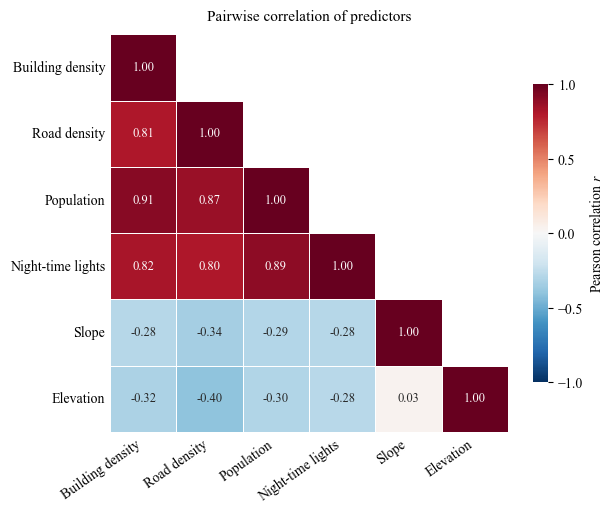

In [6]:
# readable names for the axis labels
label_map = {
    "building_density_training_new": "Building density",
    "road_per_pixel_training_new":   "Road density",
    "pop_training_new":              "Population",
    "nighttime_lights_training_new": "Night-time lights",
    "slope_training_new":            "Slope",
    "masl_training_new":             "Elevation",
}

corr_matrix = df_clean[predictor_names].corr()
corr_plot = corr_matrix.rename(index=label_map, columns=label_map)
print(corr_matrix.round(3))

# show the lower triangle incl. the diagonal, hide the redundant upper half
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)
annot = corr_plot.round(2) + 0.0          # round and kill "-0.00" artefacts

mpl.rcParams.update({
    "font.family":    "serif",
    "font.size":      10,
    "axes.titlesize": 11,
    "savefig.dpi":    300,
    "savefig.bbox":   "tight",
})

fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(
    corr_plot, mask=mask,
    annot=annot, fmt=".2f", annot_kws={"size": 9},
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.6, linecolor="white",
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation $r$",
              "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax,
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Pairwise correlation of predictors", pad=10)
fig.tight_layout()

fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "predictor_correlation.pdf")
fig.savefig(fig_dir / "predictor_correlation.png")
plt.show()


## 5. RF Training (with OOB)

In [7]:
rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    random_state=42,
    oob_score=True,
    n_jobs=-1
)
rf.fit(X, y)

# OOB-probability P(hospital) per pixel — each pixel is evaluated by the trees that did NOT see it during training
proba = rf.oob_decision_function_[:, 1]

print(f"Mean P(hospital) for hospital pixels: {proba[y == 1].mean():.4f}")
print(f"Mean P(hospital) for non-hospital pixels: {proba[y == 0].mean():.4f}")
print(f"ROC-AUC (OOB): {roc_auc_score(y, proba):.4f}")

Mean P(hospital) for hospital pixels: 0.1725
Mean P(hospital) for non-hospital pixels: 0.0049
ROC-AUC (OOB): 0.9278


In [8]:
n_pos = int(y.sum())
n_tot = len(y)
prevalence = n_pos / n_tot
ap = average_precision_score(y, proba)

print(f"Positive pixels:          {n_pos} of {n_tot}")
print(f"Prevalence (Baseline):    {prevalence:.4f}  (1:{(n_tot - n_pos) / n_pos:.1f})")
print(f"Average Precision:       {ap:.4f}")
print(f"AP / Baseline-Ratio:     {ap / prevalence:5.1f}  (theoretical Maximum: {1 / prevalence:.1f})")

Positive pixels:          540 of 92267
Prevalence (Baseline):    0.0059  (1:169.9)
Average Precision:       0.2513
AP / Baseline-Ratio:      42.9  (theoretical Maximum: 170.9)


## 6. Define threshold

### 6.1 KSS (Hanssen-Kuipers Skill Score) -- rejected

In [9]:
def hanssen_kuipers_score(y_true, y_pred):

    """KSS = sensitivity + specificity - 1.

    Also known as True Skill Statistic (TSS) or Peirce's Skill Score.
    labels=[0, 1] forces a 2x2 matrix, even if only one class is predicted at extreme thresholds.
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return sensitivity + specificity - 1, sensitivity, specificity


# Standard-cutoff 0.5 results
oob_pred_05 = np.argmax(rf.oob_decision_function_, axis=1)
print(confusion_matrix(y, oob_pred_05))
print(classification_report(y, oob_pred_05, target_names=["No hospital", "Hospital"]))

kss_05, sens_05, spec_05 = hanssen_kuipers_score(y, oob_pred_05)
print(f"At threshold 0.5: KSS = {kss_05:.4f}, "
      f"sensitivity = {sens_05:.4f}, specificity = {spec_05:.4f}")

[[91697    30]
 [  502    38]]
              precision    recall  f1-score   support

 No hospital       0.99      1.00      1.00     91727
    Hospital       0.56      0.07      0.12       540

    accuracy                           0.99     92267
   macro avg       0.78      0.54      0.56     92267
weighted avg       0.99      0.99      0.99     92267

At threshold 0.5: KSS = 0.0700, sensitivity = 0.0704, specificity = 0.9997


In [10]:
# Candidate thresholds across the entire observed probability range

CAND = np.arange(0.0001, float(proba.max()), 0.0001)

def best_kss_threshold(y_true, p, cand=CAND):
    scores = np.array([hanssen_kuipers_score(y_true, (p >= t).astype(int))[0] for t in cand])
    return cand[int(np.nanargmax(scores))], np.nanmax(scores)

thr_kss, kss_best = best_kss_threshold(y.values, proba)
_, sens_b, spec_b = hanssen_kuipers_score(y.values, (proba >= thr_kss).astype(int))
tn, fp, fn, tp = confusion_matrix(y, (proba >= thr_kss).astype(int), labels=[0, 1]).ravel()
precision_b = tp / (tp + fp) if (tp + fp) else np.nan

print(f"KSS-optimal treshold: {thr_kss:.5f}")
print(f"KSS = {kss_best:.4f}, Sensitivity = {sens_b:.4f}, Specificity = {spec_b:.4f}")
print(f"Precision = {precision_b:.4f}  (TP={tp}, FP={fp}, FN={fn})")

if thr_kss <= CAND[1] or thr_kss >= CAND[-2]:
    print("\nWARNING: Threshold lies at the edge of the search range.")

KSS-optimal treshold: 0.00480
KSS = 0.8596, Sensitivity = 0.9370, Specificity = 0.9225
Precision = 0.0665  (TP=506, FP=7106, FN=34)


### 6.2 Precision-recall-curve

In [11]:
precision, recall, thresholds = precision_recall_curve(y, proba)
ap_score = average_precision_score(y, proba)

In [12]:
pr_df = pd.DataFrame({"threshold": np.append(thresholds, 1.0),
                      "precision": precision, "recall": recall})

for target_recall in [0.1, 0.2, 0.3, 0.4, 0.5]:
    row = pr_df[pr_df["recall"] >= target_recall].iloc[-1]
    print(f"Recall >= {target_recall}: threshold={row['threshold']:.4f}, "
          f"precision={row['precision']:.4f}, recall={row['recall']:.4f}")

# F1-optimal threshold: Alternative, if the absolute number of predicted hospitals is the priority
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
i_f1 = int(np.argmax(f1))
thr_f1 = thresholds[i_f1]   # operational threshold: fixed for 8.3/8.4 and section 10
print(f"\nBest F1: threshold={thresholds[i_f1]:.4f}, "
      f"precision={precision[i_f1]:.4f}, recall={recall[i_f1]:.4f}, F1={f1[i_f1]:.4f}")

Recall >= 0.1: threshold=0.4505, precision=0.5294, recall=0.1000
Recall >= 0.2: threshold=0.3073, precision=0.3750, recall=0.2000
Recall >= 0.3: threshold=0.2289, precision=0.3260, recall=0.3000
Recall >= 0.4: threshold=0.1559, precision=0.2469, recall=0.4000
Recall >= 0.5: threshold=0.1130, precision=0.2155, recall=0.5000

Best F1: threshold=0.2182, precision=0.3157, recall=0.3204, F1=0.3180


In [13]:
def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1_ = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    i = int(np.argmax(f1_))
    return thr[i], f1_[i]

# Confirmation: gives the same value as the manual computation above
thr_f1_check, f1_check = best_f1_threshold(y.values, proba)
print(f"best_f1_threshold-function: threshold={thr_f1_check:.4f}, F1={f1_check:.4f} "
      f"(should match the above best F1)")

best_f1_threshold-function: threshold=0.2182, F1=0.3180 (should match the above best F1)


In [14]:
# Confusion matrix at the F1-optimal threshold (OOB probabilities)
oob_pred_f1 = (proba >= thr_f1).astype(int)
print(confusion_matrix(y, oob_pred_f1, labels=[0, 1]))
print(classification_report(y, oob_pred_f1, target_names=["No hospital", "Hospital"]))

tn, fp, fn, tp = confusion_matrix(y, oob_pred_f1, labels=[0, 1]).ravel()
print(f"F1-optimal threshold {thr_f1:.4f}: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

[[91352   375]
 [  367   173]]
              precision    recall  f1-score   support

 No hospital       1.00      1.00      1.00     91727
    Hospital       0.32      0.32      0.32       540

    accuracy                           0.99     92267
   macro avg       0.66      0.66      0.66     92267
weighted avg       0.99      0.99      0.99     92267

F1-optimal threshold 0.2182: TP=173, FP=375, FN=367, TN=91352


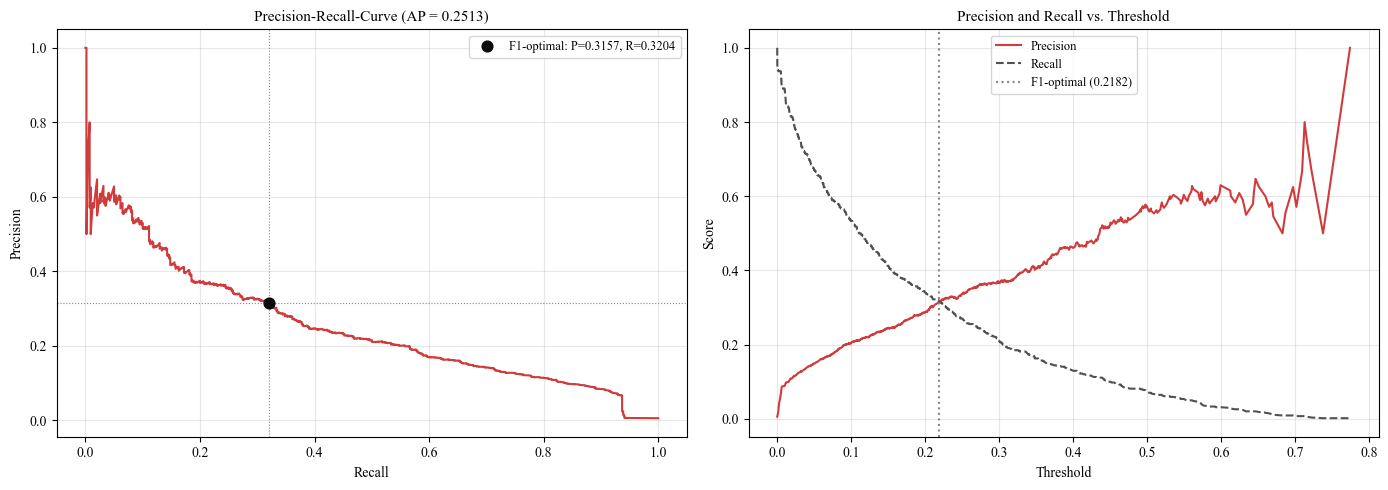

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(recall, precision, color=THEME)
axes[0].scatter(recall[i_f1], precision[i_f1], color=INK, s=60, zorder=5,
                label=f"F1-optimal: P={precision[i_f1]:.4f}, R={recall[i_f1]:.4f}")
axes[0].axhline(precision[i_f1], ls=":", color=MUTED, lw=0.8)
axes[0].axvline(recall[i_f1], ls=":", color=MUTED, lw=0.8)
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title(f"Precision-Recall-Curve (AP = {ap_score:.4f})")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(thresholds, precision[:-1], label="Precision", color=THEME)
axes[1].plot(thresholds, recall[:-1], label="Recall", color=INK_SECONDARY, ls="--")
axes[1].axvline(thr_f1, ls=":", color=MUTED, label=f"F1-optimal ({thr_f1:.4f})")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Score")
axes[1].set_title("Precision and Recall vs. Threshold")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 7. Variable Importance

Permutation importance (mean ± SD, decrease in ROC-AUC):
Population: 0.0612 ± 0.0024
Building density: 0.0180 ± 0.0003
Elevation: 0.0102 ± 0.0007
Slope: 0.0079 ± 0.0005
Night-time lights: 0.0054 ± 0.0001
Road density: 0.0020 ± 0.0000


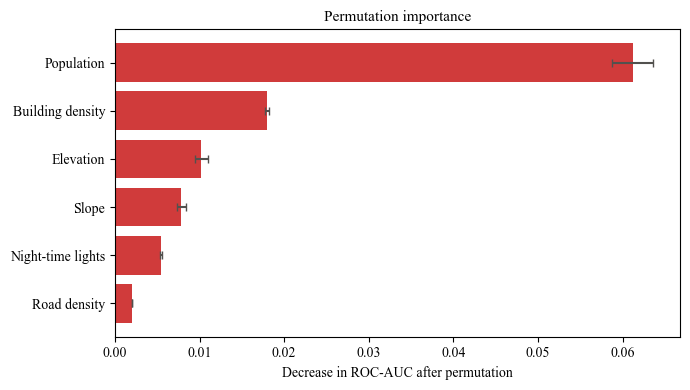

In [16]:
perm_result = permutation_importance(
    rf, X, y, n_repeats=20, random_state=42, n_jobs=-1, scoring="roc_auc")

perm_importances = pd.Series(perm_result.importances_mean,
                             index=predictor_names).sort_values(ascending=False)
perm_std = pd.Series(perm_result.importances_std, index=predictor_names)

print("Permutation importance (mean ± SD, decrease in ROC-AUC):")
for name in perm_importances.index:
    print(f"{label_map.get(name, name)}: {perm_importances[name]:.4f} ± {perm_std[name]:.4f}")

plt.figure(figsize=(7, 4))
plt.barh([label_map.get(n, n) for n in perm_importances.index[::-1]],
         perm_importances.values[::-1],
         xerr=perm_std.reindex(perm_importances.index[::-1]).values,
         color=THEME, edgecolor="none", ecolor=INK_SECONDARY, capsize=3)
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Permutation importance")
plt.tight_layout()
plt.show()

## 8. Model validation (CV)

### 8.1 Coordinates

In [17]:
#Pixelcenter coordinates from the reference transform, directly projected to EPSG:32645 (UTM 45N)

xs = ref_transform.c + (np.arange(ref_shape[1]) + 0.5) * ref_transform.a
ys = ref_transform.f + (np.arange(ref_shape[0]) + 0.5) * ref_transform.e
x_full, y_full = np.meshgrid(xs, ys)

keep = ~nodata_mask.values
tf = Transformer.from_crs("EPSG:4326", "EPSG:32645", always_xy=True)
df_clean["x_m"], df_clean["y_m"] = tf.transform(x_full.ravel()[keep],
                                                y_full.ravel()[keep])

print(f"{len(df_clean):,} cells with coordinates")

92,267 cells with coordinates


### 8.2 Differentiate between regions (Administrative units)

In [18]:
# Regions = the 8 training areas, as they were delineated and cut out as administrative units. Assignment via Point-in-Polygon.

regions = gpd.read_file(region_shp).to_crs("EPSG:32645")   # metric, like x_m/y_m

# Check for overlapping polygons
ov = gpd.sjoin(regions[["name", "geometry"]], regions[["name", "geometry"]],
               predicate="overlaps")
assert ov.empty, f"Region polygons overlap:\n{ov[['name_left', 'name_right']]}"

pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(df_clean["x_m"], df_clean["y_m"]),
                       index=df_clean.index, crs="EPSG:32645")
joined = gpd.sjoin(pts, regions[["name", "number", "geometry"]],
                   how="left", predicate="within")
assert len(joined) == len(df_clean), "Pixels assigned more than once (polygons not disjoint?)"

df_clean["region"] = joined["name"].values
df_clean["region_id"] = joined["number"].values

# Each training pixel must lie in exactly one region
n_missing = int(df_clean["region"].isna().sum())
assert n_missing == 0, f"{n_missing} Pixel outside any region polygon"
assert df_clean["region"].nunique() == len(regions), \
    f"{df_clean['region'].nunique()} of {len(regions)} regions contain pixels"

region_summary = df_clean.groupby("region").agg(
    n_cells=("hospital", "size"),
    n_pos=("hospital", "sum"),
    x_km=("x_m", lambda s: (s.max() - s.min()) / 1000),
    y_km=("y_m", lambda s: (s.max() - s.min()) / 1000))
print(region_summary.round(1))
print(f"\n{len(regions)} regions, all {len(df_clean):,} pixels assigned, "
      f"n_pos total = {int(region_summary.n_pos.sum())} "
      f"(= {int(df_clean.hospital.sum())} Hospital-pixels)")

                                         n_cells  n_pos   x_km   y_km
region                                                               
Dolpa                                      42425   40.0  125.5  110.3
Humla                                      32407   51.0  118.2   93.7
Kailash and Raksirang 03, 04, 05 and 09     1665   11.0   22.5   19.3
Kalikot                                     8752   63.0   52.3   54.3
Kathmandu and Kathmandu Valley              3826  283.0   37.1   31.3
Mithila Bihari                               193   10.0    7.9    9.7
Namobuddha                                   542   14.0   15.6    9.7
Pokhara                                     2457   68.0   33.5   28.8

8 regions, all 92,267 pixels assigned, n_pos total = 540 (= 540 Hospital-pixels)


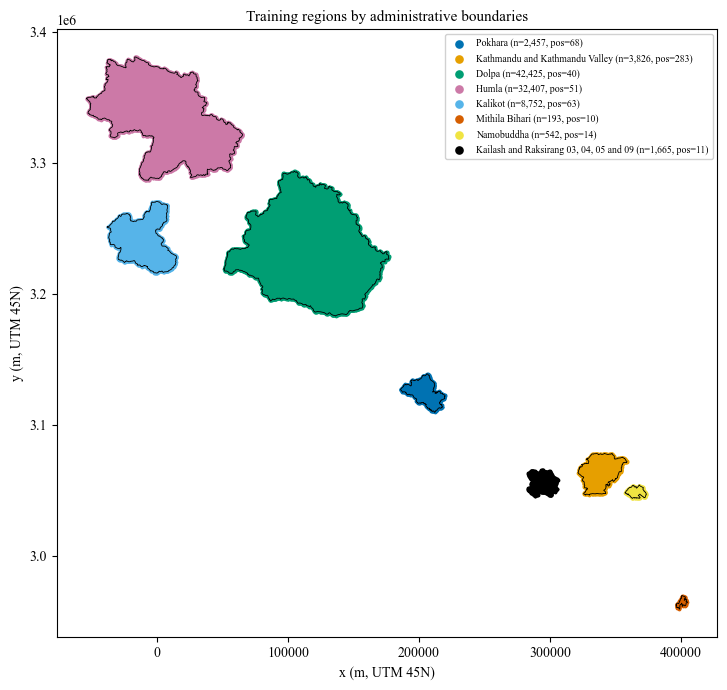

In [19]:
# Visual control

def polygon_rings(geom):
    """Outer and inner rings of a (multi)polygon as (xs, ys)."""
    parts = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
    for poly in parts:
        yield poly.exterior.xy
        for hole in poly.interiors:
            yield hole.xy


fig, ax = plt.subplots(figsize=(9, 7))
region_colors = REGION_COLORS

for k, name in enumerate(regions.sort_values("number")["name"]):
    sub = df_clean[df_clean["region"] == name]
    ax.scatter(sub["x_m"], sub["y_m"], s=3, color=region_colors[k % len(region_colors)],
               label=f"{name} (n={len(sub):,}, pos={int(sub.hospital.sum())})")

for geom in regions.geometry:
    for xs, ys in polygon_rings(geom):
        ax.plot(xs, ys, color="black", linewidth=0.6, zorder=3)

ax.set_aspect("equal")
ax.set_title("Training regions by administrative boundaries")
ax.set_xlabel("x (m, UTM 45N)")
ax.set_ylabel("y (m, UTM 45N)")
ax.legend(fontsize=7, markerscale=3, framealpha=0.9)
plt.tight_layout(); plt.show()

### 8.3 Leave-one-region-out

In [20]:
def evaluate(y_true, p, thr):
    """Indicators at threshold thr + threshold-independent rank quality.

    F1 = 2TP / (n_pos + n_pred): is also defined (= 0), if the model predicts nothing or only false positives.
    """
    pred = p >= thr
    n_pos, n_pred = int(y_true.sum()), int(pred.sum())
    tp = int((pred & (y_true == 1)).sum())
    prevalence = n_pos / len(y_true)
    ap = average_precision_score(y_true, p)
    return dict(
        n_cells=len(y_true), n_pos=n_pos, n_pred=n_pred, tp=tp,
        recall=tp / n_pos if n_pos else np.nan,
        precision=tp / n_pred if n_pred else np.nan,
        f1=2 * tp / (n_pos + n_pred) if (n_pos + n_pred) else np.nan,
        auc=roc_auc_score(y_true, p),
        ap=ap,
        # AP relative to the baseline prevalence of the region: 
        # rank quality comparable between regions with very different hospital density
        ap_lift=ap / prevalence,
        # Probability level of the true hospital pixels
        p_pos_mean=p[y_true == 1].mean())


rows = []
for held_out in sorted(df_clean.region.unique()):
    tr = df_clean[df_clean.region != held_out]
    te = df_clean[df_clean.region == held_out]

    m = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                               random_state=42, oob_score=True, n_jobs=-1)
    m.fit(tr[predictor_names], tr["hospital"].astype(int))
    p = m.predict_proba(te[predictor_names])[:, 1]
    y_tr = tr["hospital"].astype(int).values
    y_te = te["hospital"].astype(int).values
    oob_tr = m.oob_decision_function_[:, 1]

    # Thresholds for the held-out region are determined from the training data (OOB)
    thr, _ = best_f1_threshold(y_tr, oob_tr)
    r = evaluate(y_te, p, thr)
    r.update(held_out=held_out, threshold=thr)
    rows.append(r)

loco = pd.DataFrame(rows)[["held_out", "n_cells", "n_pos", "n_pred", "tp", "threshold",
                           "recall", "precision", "f1", "auc", "ap", "ap_lift", "p_pos_mean"]]
print(loco.round(3).to_string(index=False))

# Mean over the 8 regions: each region counts equally, regardless of its size. 
# NaN (precision without any prediction) is omitted.
loco_mean = loco.drop(columns="held_out").mean()
print("\nLORO mean over 8 regions:", loco_mean.round(3).to_dict())

                               held_out  n_cells  n_pos  n_pred  tp  threshold  recall  precision    f1   auc    ap  ap_lift  p_pos_mean
                                  Dolpa    42425     40      30   6      0.179   0.150      0.200 0.171 0.921 0.162  171.516       0.093
                                  Humla    32407     51      16   7      0.199   0.137      0.438 0.209 0.915 0.220  139.932       0.076
Kailash and Raksirang 03, 04, 05 and 09     1665     11       1   1      0.171   0.091      1.000 0.167 0.832 0.160   24.150       0.053
                                Kalikot     8752     63      61   9      0.180   0.143      0.148 0.145 0.864 0.098   13.650       0.079
         Kathmandu and Kathmandu Valley     3826    283      97  12      0.178   0.042      0.124 0.063 0.724 0.134    1.817       0.070
                         Mithila Bihari      193     10       0   0      0.209   0.000        NaN 0.000 0.800 0.136    2.628       0.010
                             Namobuddha  

## 9. Area of Applicability

Method: Meyer & Pebesma (2021), *Predicting into unknown space? Estimating the area of applicability of spatial prediction models*, Methods in Ecology and Evolution.

### 9.1 Functions

In [21]:
CHUNK = 200_000   # pixels per block in the NN search
NODATA = -1



def load_nepal(nepal_paths, nodata_values=(-1, -9999)):
    """Crop the Nepal-wide predictor rasters to their common intersection.
    """
    metas = []
    for path in nepal_paths:
        with rasterio.open(path) as src:
            metas.append((src.bounds, src.transform, src.crs, src.res))

    assert len({m[2] for m in metas}) == 1, "CRS differs"
    assert len({(round(m[3][0], 8), round(m[3][1], 8)) for m in metas}) == 1, \
        "Resolution differs"

    # common intersection
    left   = max(m[0].left   for m in metas)
    right  = min(m[0].right  for m in metas)
    bottom = max(m[0].bottom for m in metas)
    top    = min(m[0].top    for m in metas)
    print(f"Intersection: {left:.6f}–{right:.6f} / {bottom:.6f}–{top:.6f}")

    stack, profile, shape = [], None, None
    for path in nepal_paths:
        with rasterio.open(path) as src:
            win = from_bounds(left, bottom, right, top, src.transform)
            win = win.round_offsets().round_lengths()
            arr = src.read(1, window=win).astype(np.float32)

            if profile is None:
                shape = arr.shape
                profile = src.profile.copy()
                profile.update(height=shape[0], width=shape[1],
                               transform=src.window_transform(win))
            else:
                assert arr.shape == shape, \
                    f"Still different after cropping: {path} {arr.shape} vs {shape}"
            stack.append(arr)

    arr = np.stack(stack, axis=-1).reshape(-1, len(nepal_paths))

    valid = np.isfinite(arr).all(axis=1)
    for nd in nodata_values:
        valid &= (arr != nd).all(axis=1)

    print(f"Nepal: {shape[0]}x{shape[1]} = {shape[0]*shape[1]:,} cells, "
          f"of which {valid.sum():,} valid ({100*valid.mean():.1f}%)")
    return arr, valid, profile, shape


def compute_aoa(train_X, new_X, weights=None, sample_for_dbar=2000, seed=42):
    """Dissimilarity index and AOA threshold according to Meyer & Pebesma (2021).

    1. Scale the predictors with the training mean/SD
    2. Optionally weight them with the variable importance
    3. DI = distance to the nearest training point / mean training distance
    4. Threshold from the leave-one-out distribution of the training DI: Q75 + 1.5*IQR
    """
    rng = np.random.default_rng(seed)

    mu, sd = train_X.mean(axis=0), train_X.std(axis=0)
    sd[sd < 1e-9] = 1.0

    w = np.ones(train_X.shape[1]) if weights is None else np.asarray(weights, float)
    w = w / w.sum() * len(w)

    tr = (train_X - mu) / sd * np.sqrt(w)

    idx = rng.choice(len(tr), min(sample_for_dbar, len(tr)), replace=False)
    d_bar = pdist(tr[idx]).mean()

    nn = NearestNeighbors(n_neighbors=2, n_jobs=-1).fit(tr)

    d_tr, _ = nn.kneighbors(tr)
    di_train = d_tr[:, 1] / d_bar
    q25, q75 = np.percentile(di_train, [25, 75])
    threshold = q75 + 1.5 * (q75 - q25)

    di_new = np.empty(len(new_X), dtype=np.float32)
    for s in range(0, len(new_X), CHUNK):
        block = (new_X[s:s + CHUNK] - mu) / sd * np.sqrt(w)
        d, _ = nn.kneighbors(block, n_neighbors=1)
        di_new[s:s + CHUNK] = d[:, 0] / d_bar

    return di_new, threshold, di_train



def univariate_coverage(train_X, new_X, names, q=(1, 99)):
    """Per predictor: share of Nepal pixels outside the training range."""
    rows = []
    for k, name in enumerate(names):
        lo_a, hi_a = train_X[:, k].min(), train_X[:, k].max()
        lo_q, hi_q = np.percentile(train_X[:, k], q)
        rows.append({
            "predictor": name, "train_min": lo_a, "train_max": hi_a,
            "outside_range_pct": 100 * np.mean((new_X[:, k] < lo_a) | (new_X[:, k] > hi_a)),
            "outside_p1_p99_pct": 100 * np.mean((new_X[:, k] < lo_q) | (new_X[:, k] > hi_q)),
        })
    return pd.DataFrame(rows)


def write_raster(values, valid, shape, profile, out_path, dtype="float32"):
    """Values back into the raster layout, invalid pixels set to NODATA."""
    full = np.full(shape[0] * shape[1], NODATA, dtype=np.float32)
    full[valid] = values
    profile.update(dtype=dtype, count=1, nodata=NODATA, compress="lzw")
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(full.reshape(shape).astype(dtype), 1)
    print(f"written: {out_path}")

### 9.2 Load Nepal rasters

In [22]:
nepal_dir = r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region"

# ADJUST: same order as predictor_names
nepal_names = ["building_density_osm", "road_per_pixel", "pop_resampled_to_ntl",
               "nighttime_lights_nepal", "slope_clipped_aligned", "masl_clipped_aligned"]
nepal_paths = [f"{nepal_dir}\\{n}.tif" for n in nepal_names]

info = []
for n, path in zip(nepal_names, nepal_paths):
    with rasterio.open(path) as src:
        info.append({
            "name": n,
            "shape": src.shape,
            "crs": str(src.crs),
            "res_x": round(src.transform.a, 8),
            "res_y": round(src.transform.e, 8),
            "left": round(src.bounds.left, 6),
            "top": round(src.bounds.top, 6),
            "right": round(src.bounds.right, 6),
            "bottom": round(src.bounds.bottom, 6),
            "nodata": src.nodata,
        })
print(pd.DataFrame(info).to_string(index=False))

print("\nMapping training -> Nepal:")
for tn, nn_ in zip(predictor_names, nepal_names):
    print(f"{tn:40s} -> {nn_}")

nepal_arr, nepal_valid, nepal_profile, nepal_shape = load_nepal(nepal_paths)
X_new = nepal_arr[nepal_valid]

                  name       shape       crs    res_x     res_y      left       top     right    bottom  nodata
  building_density_osm (985, 1956) EPSG:4326 0.004167 -0.004167 80.054167 30.450000 88.204167 26.345833    -1.0
        road_per_pixel (983, 1954) EPSG:4326 0.004167 -0.004167 80.058333 30.445833 88.200000 26.350000    -1.0
  pop_resampled_to_ntl (985, 1956) EPSG:4326 0.004167 -0.004167 80.054167 30.450000 88.204167 26.345833 -9999.0
nighttime_lights_nepal (985, 1956) EPSG:4326 0.004167 -0.004167 80.054167 30.450000 88.204167 26.345833 -9999.0
 slope_clipped_aligned (983, 1954) EPSG:4326 0.004167 -0.004167 80.058333 30.445833 88.200000 26.350000    -1.0
  masl_clipped_aligned (983, 1954) EPSG:4326 0.004167 -0.004167 80.058333 30.445833 88.200000 26.350000    -1.0

Mapping training -> Nepal:
building_density_training_new            -> building_density_osm
road_per_pixel_training_new              -> road_per_pixel
pop_training_new                         -> pop_resampled_to_ntl

### 9.3 Compute AOA

Weighting of the dissimilarity index with the permutation importance from section 7 — deviations in `pop` (dominant) thus count more than deviations in `masl` (hardly any influence on the model).

**Region balancing:** Kalikot, Humla and Dolpa together provide ~91% of all training pixels (32'407 + 42'425 + 8'752 of 92'267) — huge remote regions with rather homogeneous terrain produce many almost identical pixel combinations. We cap the three large regions at the size of the largest "normal" region (Kathmandu, ~3800 pixels) and compare the result directly with the unbalanced computation.

In [23]:
CAP_PER_REGION = 4000
rng = np.random.default_rng(42)

balanced_idx = []
for region, group in df_clean.groupby("region"):
    idx = group.index.values
    if len(idx) > CAP_PER_REGION:
        idx = rng.choice(idx, CAP_PER_REGION, replace=False)
    balanced_idx.append(idx)
balanced_idx = np.concatenate(balanced_idx)

train_X_balanced = df_clean.loc[balanced_idx, predictor_names].values.astype(np.float32)

print(f"Training pixels: {len(X):,} (original) -> {len(train_X_balanced):,} (region-balanced)\n")
vergleich_n = pd.DataFrame({
    "vorher": df_clean.groupby("region").size(),
    "nachher": pd.Series(balanced_idx).map(df_clean["region"]).value_counts().sort_index(),
})
print(vergleich_n)

Training pixels: 92,267 (original) -> 20,683 (region-balanced)

                                         vorher  nachher
Dolpa                                     42425     4000
Humla                                     32407     4000
Kailash and Raksirang 03, 04, 05 and 09    1665     1665
Kalikot                                    8752     4000
Kathmandu and Kathmandu Valley             3826     3826
Mithila Bihari                              193      193
Namobuddha                                  542      542
Pokhara                                    2457     2457


In [24]:
# Weighting with permutation importance
w = np.clip(perm_importances.reindex(predictor_names).values, 0, None) + 1e-6

# Reference: unbalanced set
train_X_raw = X.values.astype(np.float32)
di_raw, aoa_thr_raw, _ = compute_aoa(train_X_raw, X_new, weights=w)

print("Unbalanced (reference):")
print(f"  AOA threshold: {aoa_thr_raw:.4f}  | within AOA: {100*(di_raw <= aoa_thr_raw).mean():5.1f}%"
      f"  ({(di_raw <= aoa_thr_raw).sum():,} of {len(di_raw):,} pixels)")

# From here on: the region-balanced set becomes the official train_X for the rest
train_X = train_X_balanced

di, aoa_thr, di_train = compute_aoa(train_X, X_new, weights=w)

in_aoa = di <= aoa_thr

print("\nRegion-balanced (cap=4000/region, used from here on):")
print(f"  AOA threshold: {aoa_thr:.4f}  | within AOA: {100*in_aoa.mean():5.1f}%"
      f"  ({in_aoa.sum():,} of {len(in_aoa):,} pixels)")

Unbalanced (reference):
  AOA threshold: 0.0096  | within AOA:  41.0%  (320,825 of 781,696 pixels)

Region-balanced (cap=4000/region, used from here on):
  AOA threshold: 0.0925  | within AOA:  94.8%  (740,724 of 781,696 pixels)


### 9.3b Sensitivity analysis: does the result depend on the chosen cap?

In [25]:
cap_values = [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 20000, None]
rng_sens = np.random.default_rng(42)

rows = []
for cap in cap_values:
    if cap is None:
        idx = df_clean.index.values
    else:
        parts = []
        for region, group in df_clean.groupby("region"):
            gidx = group.index.values
            if len(gidx) > cap:
                gidx = rng_sens.choice(gidx, cap, replace=False)
            parts.append(gidx)
        idx = np.concatenate(parts)

    tX = df_clean.loc[idx, predictor_names].values.astype(np.float32)
    di_c, thr_c, _ = compute_aoa(tX, X_new, weights=w)
    rows.append({
        "cap": cap if cap is not None else "unbalanciert",
        "n_train": len(tX),
        "aoa_schwelle": thr_c,
        "in_aoa_pct": 100 * (di_c <= thr_c).mean(),
    })

cap_sens = pd.DataFrame(rows)
print(cap_sens.round(2).to_string(index=False))

         cap  n_train  aoa_schwelle  in_aoa_pct
        1000     6735          0.13       96.23
        2000    12400          0.10       95.62
        3000    16857          0.10       95.62
        4000    20683          0.09       94.75
        5000    23683          0.09       92.62
        6000    26683          0.08       90.23
        7000    29683          0.07       86.27
        8000    32683          0.06       82.24
        9000    35435          0.05       77.57
       10000    37435          0.05       74.22
       20000    57435          0.02       50.14
unbalanciert    92267          0.01       41.04


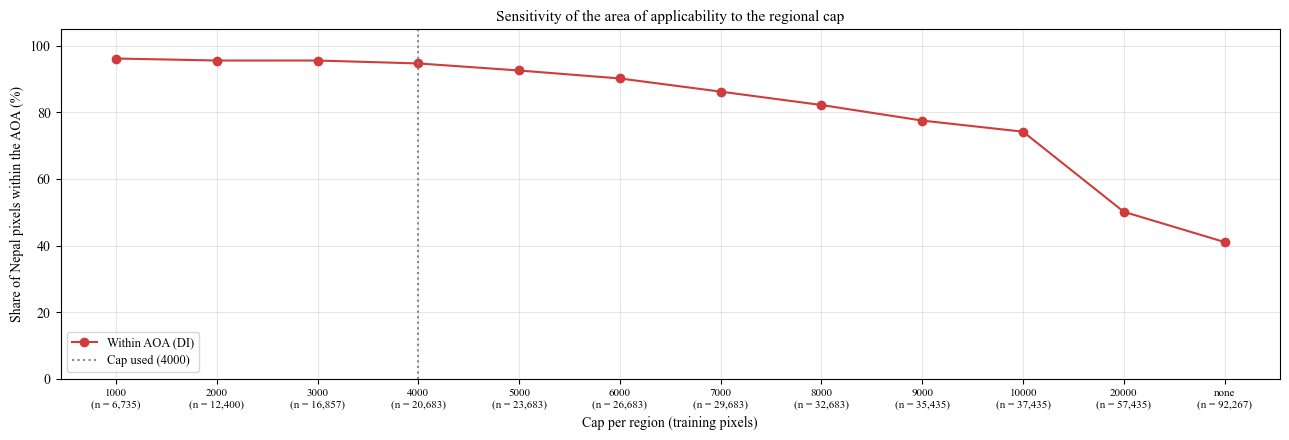

In [26]:
# Sensitivity of the AOA to the cap
cap_labels = [str(c) if c != "unbalanciert" else "none" for c in cap_sens["cap"]]
xpos = np.arange(len(cap_sens))
i_used = cap_values.index(CAP_PER_REGION)

fig, ax = plt.subplots(figsize=(13, 4.5))

ax.plot(xpos, cap_sens["in_aoa_pct"], marker="o", color=THEME, label="Within AOA (DI)")
ax.axvline(i_used, ls=":", color=MUTED, label=f"Cap used ({CAP_PER_REGION})")

ax.set_xticks(xpos)
ax.set_xticklabels([f"{l}\n(n = {n:,})" for l, n in zip(cap_labels, cap_sens["n_train"])],
                   fontsize=8)
ax.set_xlabel("Cap per region (training pixels)")
ax.set_ylabel("Share of Nepal pixels within the AOA (%)")
ax.set_ylim(0, 105)
ax.set_title("Sensitivity of the area of applicability to the regional cap")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")

plt.tight_layout(); plt.show()

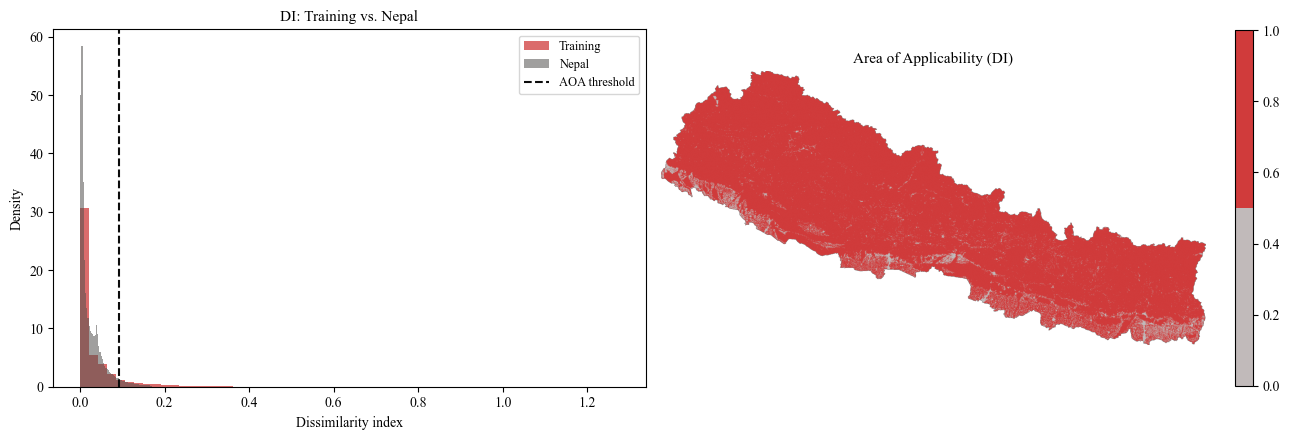

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(di_train, bins=60, alpha=.75, density=True, color=THEME, label="Training")
axes[0].hist(di[di < np.percentile(di, 99)], bins=60, alpha=.55, density=True, color=INK_SECONDARY, label="Nepal")
axes[0].axvline(aoa_thr, ls="--", color=INK, label="AOA threshold")
axes[0].set_xlabel("Dissimilarity index"); axes[0].set_ylabel("Density")
axes[0].set_title("DI: Training vs. Nepal"); axes[0].legend()

di_map = np.full(nepal_shape[0] * nepal_shape[1], np.nan)
di_map[nepal_valid] = np.where(in_aoa, 1, 0)
im = axes[1].imshow(di_map.reshape(nepal_shape), cmap=BINARY_CMAP, vmin=0, vmax=1)
axes[1].set_title("Area of Applicability (DI)"); axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=.03)

plt.tight_layout(); plt.show()

### 9.4 Write rasters

In [28]:
write_raster(in_aoa.astype(np.float32), nepal_valid, nepal_shape,
             nepal_profile.copy(), f"{nepal_dir}\\aoa_mask.tif")
write_raster(di, nepal_valid, nepal_shape,
             nepal_profile.copy(), f"{nepal_dir}\\aoa_di.tif")

written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\aoa_mask.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\aoa_di.tif


## 10. Nepal-wide prediction

The trained model is applied to all of Nepal. Each step is computed in two variants and shown directly side by side:

- **AOA**: only pixels within the area of applicability.
- **Nepal**: all valid Nepal pixels, without AOA restriction.

### 10.1 Predict probabilities

In [29]:
proba_nepal = rf.predict_proba(pd.DataFrame(X_new, columns=predictor_names))[:, 1]

n_grid = nepal_shape[0] * nepal_shape[1]

# Probability on the full Nepal grid (NaN = invalid pixel)
prob_full = np.full(n_grid, np.nan)
prob_full[nepal_valid] = proba_nepal

# The two variants as boolean masks on the full grid
aoa_full_mask = nepal_valid.copy()
aoa_full_mask[nepal_valid] = in_aoa            # valid AND within AOA
variants = {
    "AOA": aoa_full_mask,
    "Nepal": nepal_valid.copy(),               # all valid pixels, without AOA
}

summary_101 = pd.DataFrame({
    name: {
        "n_pixel": int(mask.sum()),
        "anteil_gueltig_pct": 100 * mask.sum() / nepal_valid.sum(),
        "p_min": prob_full[mask].min(),
        "p_max": prob_full[mask].max(),
        "p_mean": prob_full[mask].mean(),
    }
    for name, mask in variants.items()
}).T
print(summary_101.round(4).to_string())

        n_pixel  anteil_gueltig_pct  p_min  p_max  p_mean
AOA    740724.0             94.7586    0.0   0.92  0.0057
Nepal  781696.0            100.0000    0.0   0.92  0.0081


### 10.2 Write and visualise rasters

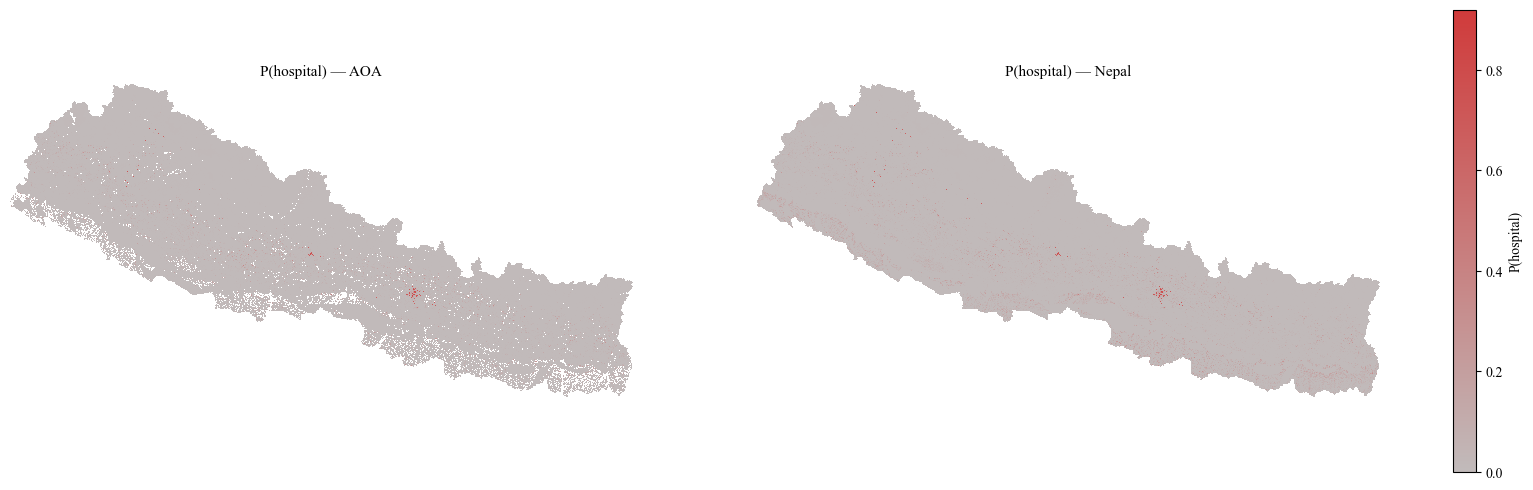

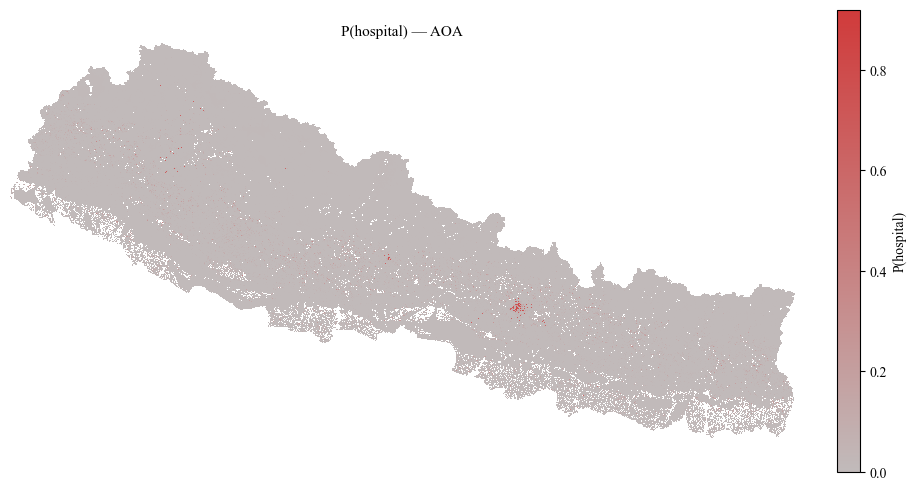

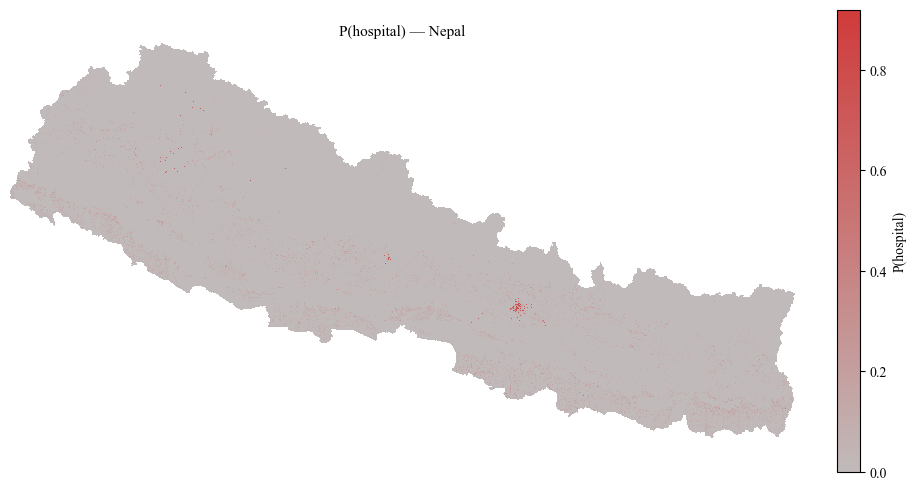

written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_probability_aoa.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_probability_nepal.tif


In [30]:
vmax = np.nanmax(prob_full)



def plot_probability(ax, name, mask):
    m = np.where(mask, prob_full, np.nan)
    ax.set_title(f"P(hospital) — {name}")
    ax.axis("off")
    return ax.imshow(m.reshape(nepal_shape), cmap=THEME_CMAP, vmin=0, vmax=vmax,
                     interpolation="nearest")


# Both variants side by side
fig, axes = plt.subplots(1, 2, figsize=(19, 6))
for ax, (name, mask) in zip(axes, variants.items()):
    im = plot_probability(ax, name, mask)
plt.colorbar(im, ax=axes, fraction=.02, label="P(hospital)")
plt.show()

# Each variant separately (same colour scale)
for name, mask in variants.items():
    fig, ax = plt.subplots(figsize=(11, 6))
    im = plot_probability(ax, name, mask)
    plt.colorbar(im, ax=ax, fraction=.03, label="P(hospital)")
    plt.show()

for name, mask in variants.items():
    write_raster(prob_full[mask], mask, nepal_shape, nepal_profile.copy(),
                 f"{nepal_dir}\\hospital_probability_{name.lower()}.tif")

### 10.3 Candidate masks (F1 threshold)

thr_f1 = 0.2182

AOA   : 1,086 candidate pixels (0.15% of the area)
Nepal : 1,582 candidate pixels (0.20% of the area)
Of which outside the AOA: 496


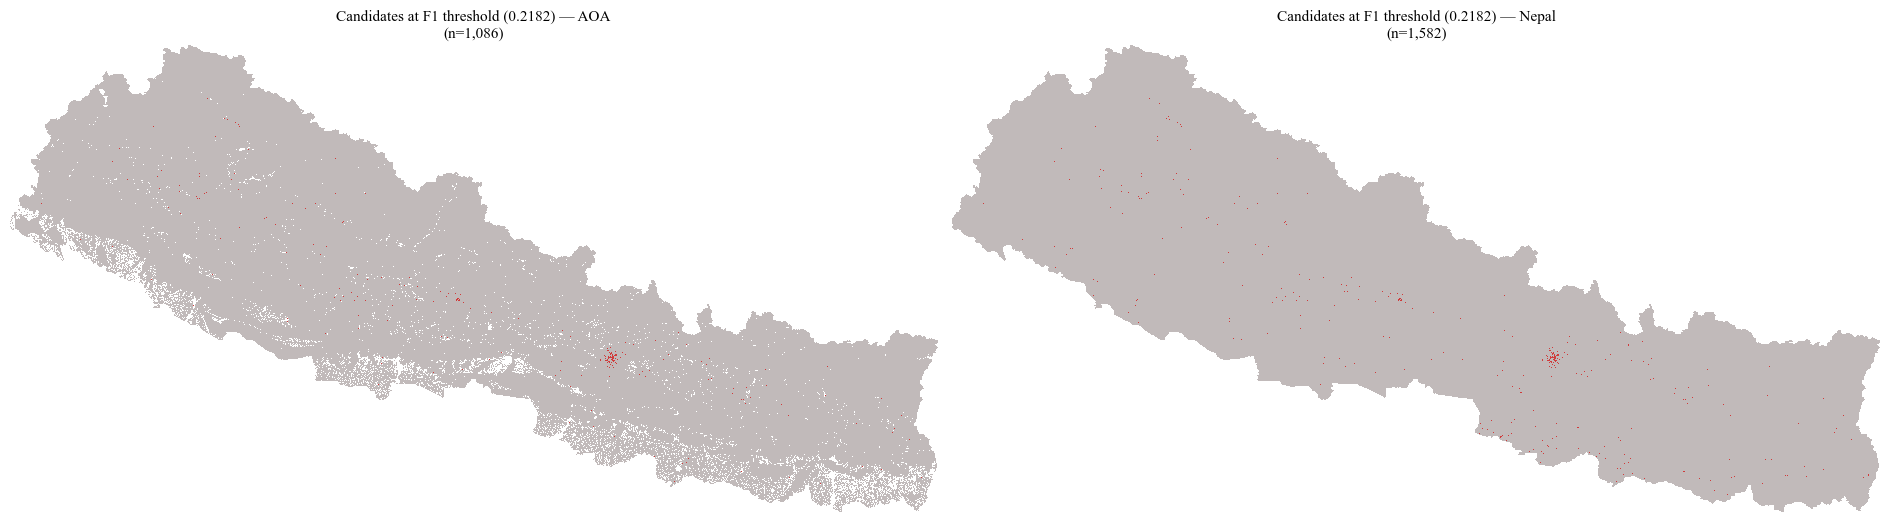

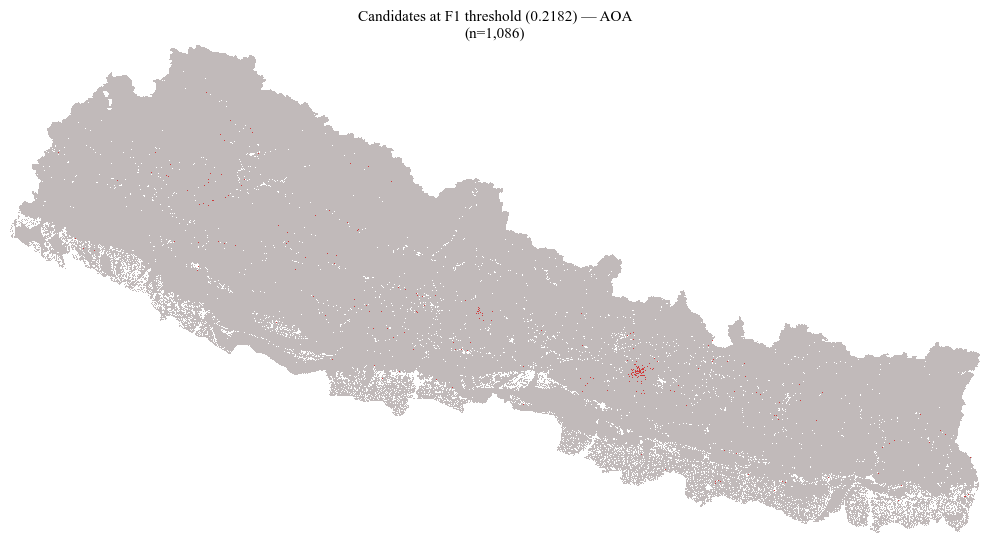

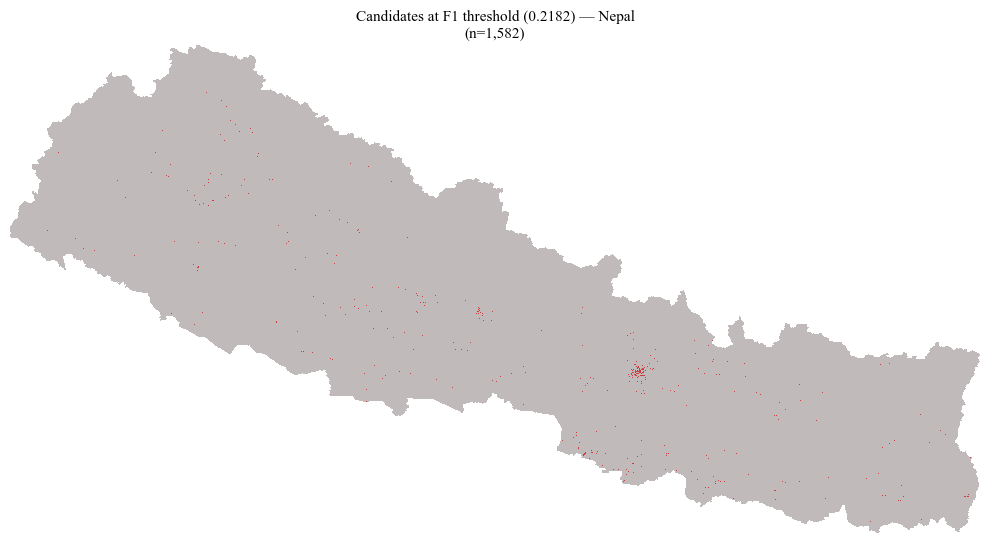

written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_candidates_f1_aoa.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_candidates_f1_nepal.tif


In [31]:
print(f"thr_f1 = {thr_f1:.4f}\n")

cand_f1_full = np.zeros(n_grid, dtype=bool)
cand_f1_full[nepal_valid] = proba_nepal >= thr_f1

cand = {name: cand_f1_full & mask for name, mask in variants.items()}

for name, mask in variants.items():
    n_c = cand[name].sum()
    print(f"{name:6s}: {n_c:,} candidate pixels ({100*n_c/mask.sum():.2f}% of the area)")
print(f"Of which outside the AOA: {(cand['Nepal'] & ~aoa_full_mask).sum():,}")



def plot_candidates(ax, name, mask):
    m = np.full(n_grid, np.nan)
    m[mask] = cand[name][mask]
    ax.imshow(m.reshape(nepal_shape), cmap=BINARY_CMAP, vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(f"Candidates at F1 threshold ({thr_f1:.4f}) — {name}\n(n={cand[name].sum():,})")
    ax.axis("off")


# Both variants side by side
fig, axes = plt.subplots(1, 2, figsize=(19, 6))
for ax, (name, mask) in zip(axes, variants.items()):
    plot_candidates(ax, name, mask)
plt.tight_layout(); plt.show()

# Each variant separately
for name, mask in variants.items():
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_candidates(ax, name, mask)
    plt.tight_layout(); plt.show()

for name, mask in variants.items():
    write_raster(cand[name][mask].astype(np.float32), mask, nepal_shape,
                 nepal_profile.copy(), f"{nepal_dir}\\hospital_candidates_f1_{name.lower()}.tif")

### 10.4 Actual health facilities

In [32]:
hospitals_path = r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\input_sets\hospitals_01.tif"

with rasterio.open(hospitals_path) as src:
    assert src.shape == nepal_shape, f"Shape mismatch: {src.shape} vs {nepal_shape}"
    assert transforms_close(src.transform, nepal_profile["transform"]), \
        f"Transform mismatch: {src.transform}"
    hosp_actual_full = src.read(1).flatten()

hosp_actual_bool = hosp_actual_full == 1

n_hosp_total = hosp_actual_bool.sum()
print(f"Actual hospital pixels in the raster: {n_hosp_total:,}")
for name, mask in variants.items():
    n_h = (hosp_actual_bool & mask).sum()
    print(f"  of which {name:6s}: {n_h:,} ({100*n_h/n_hosp_total:.1f}%)")

Actual hospital pixels in the raster: 1,801
  of which AOA   : 1,108 (61.5%)
  of which Nepal : 1,801 (100.0%)


### 10.5 Exclude training areas

In [33]:
# Pixel centres of the training pixels in degrees (EPSG:4326), same order as df_clean (8.1)
x_deg = x_full.ravel()[keep]
y_deg = y_full.ravel()[keep]

nt = nepal_profile["transform"]
col = np.floor((x_deg - nt.c) / nt.a).astype(int)
row = np.floor((y_deg - nt.f) / nt.e).astype(int)

in_grid = (row >= 0) & (row < nepal_shape[0]) & (col >= 0) & (col < nepal_shape[1])
assert in_grid.all(), f"{(~in_grid).sum()} training pixels outside the Nepal grid"

flat_idx = row * nepal_shape[1] + col
assert len(np.unique(flat_idx)) == len(df_clean), "Several training pixels on the same Nepal cell"

train_mask_full = np.zeros(n_grid, dtype=bool)
train_mask_full[flat_idx] = True
print(f"Nepal pixels masked as training area: {train_mask_full.sum():,}")

# Alignment check: training hospitals should also be hospitals in the Nepal raster
match = hosp_actual_bool[flat_idx[df_clean["hospital"].values == 1]].mean()
print(f"Training hospital pixels that are also hospitals in hospitals_01.tif: {100*match:.1f}%")

eval_masks = {name: mask & ~train_mask_full for name, mask in variants.items()}

summary_105 = pd.DataFrame({
    name: {
        "n_pixel_eval": int(em.sum()),
        "anteil_der_variante_pct": 100 * em.sum() / variants[name].sum(),
        "spitaeler_tatsaechlich": int((hosp_actual_bool & em).sum()),
        "kandidaten_f1": int((cand_f1_full & em).sum()),
    }
    for name, em in eval_masks.items()
}).T
print("\nEvaluable area (without training areas):")
print(summary_105.round(1).to_string())

Nepal pixels masked as training area: 92,267


Training hospital pixels that are also hospitals in hospitals_01.tif: 100.0%

Evaluable area (without training areas):
       n_pixel_eval  anteil_der_variante_pct  spitaeler_tatsaechlich  kandidaten_f1
AOA        648680.0                     87.6                   599.0          567.0
Nepal      689429.0                     88.2                  1261.0         1032.0


### 10.6 Maps: actual hospitals and F1 prediction (without training areas)

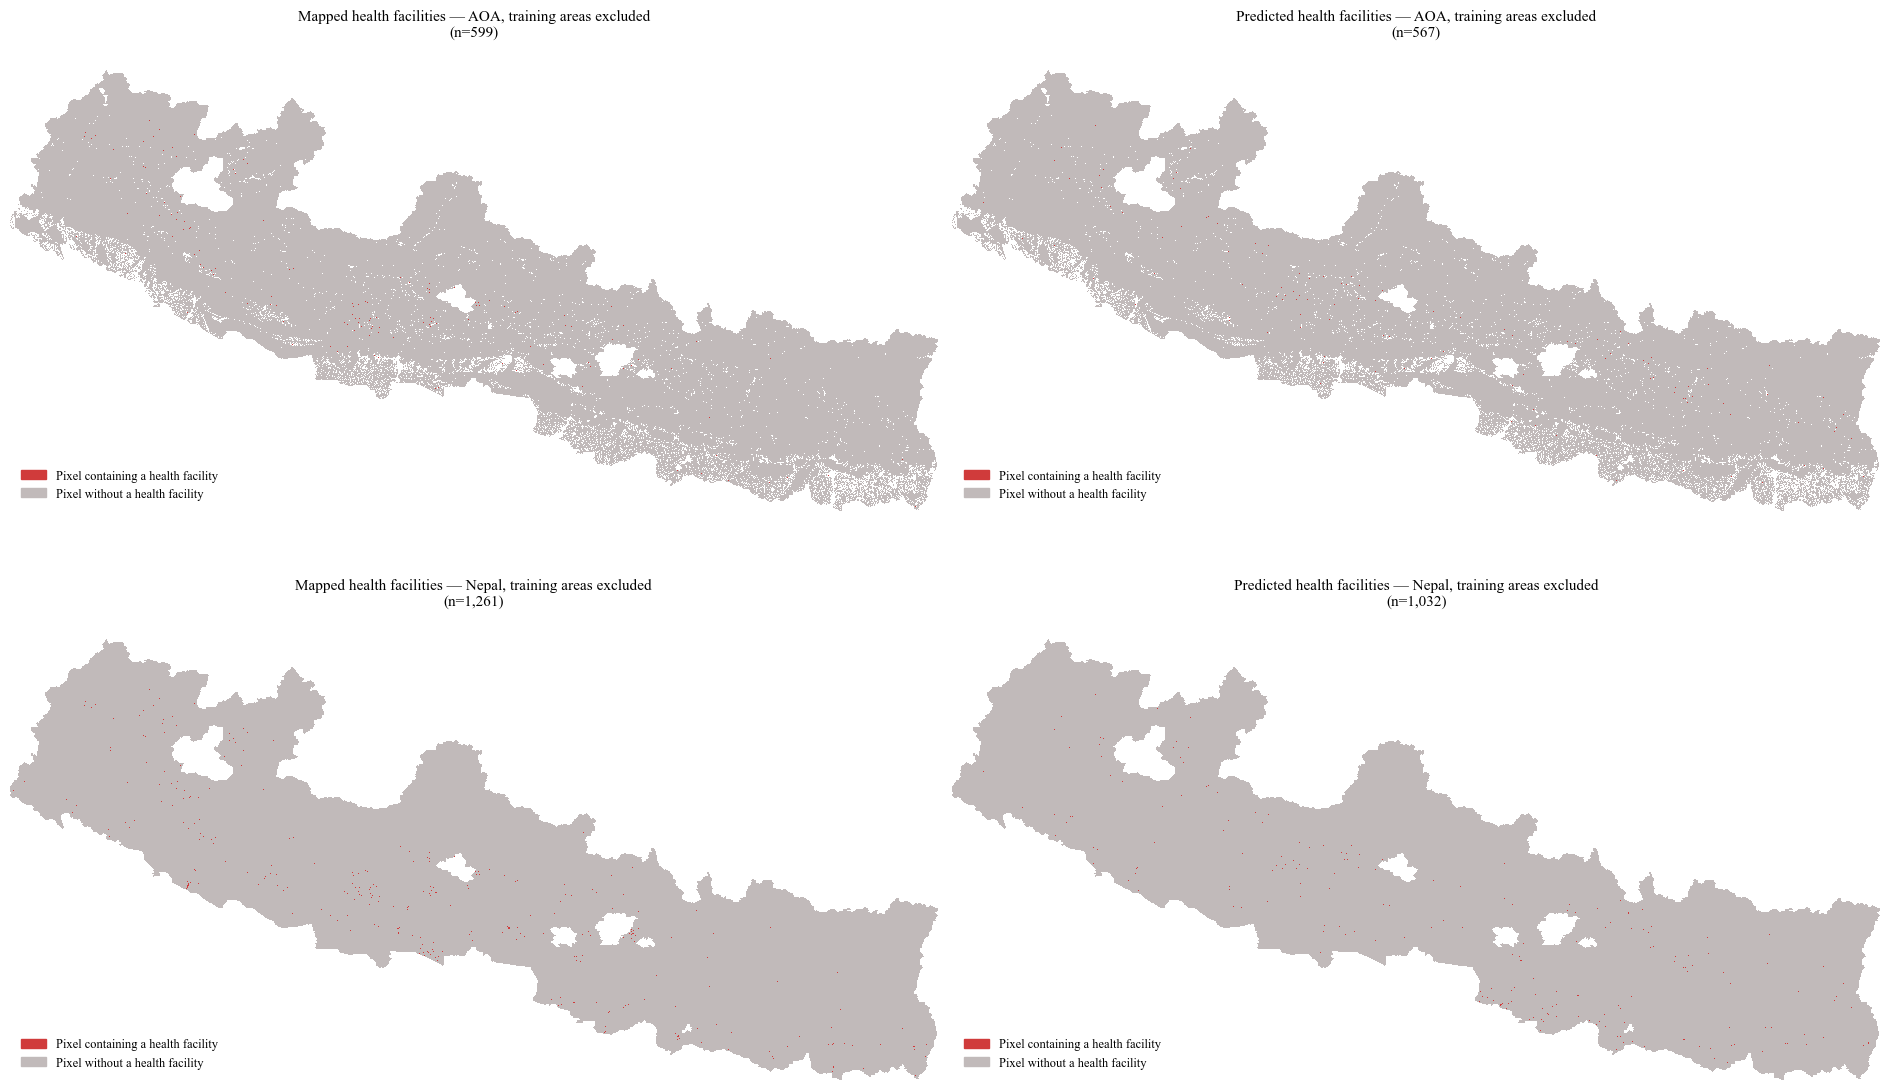

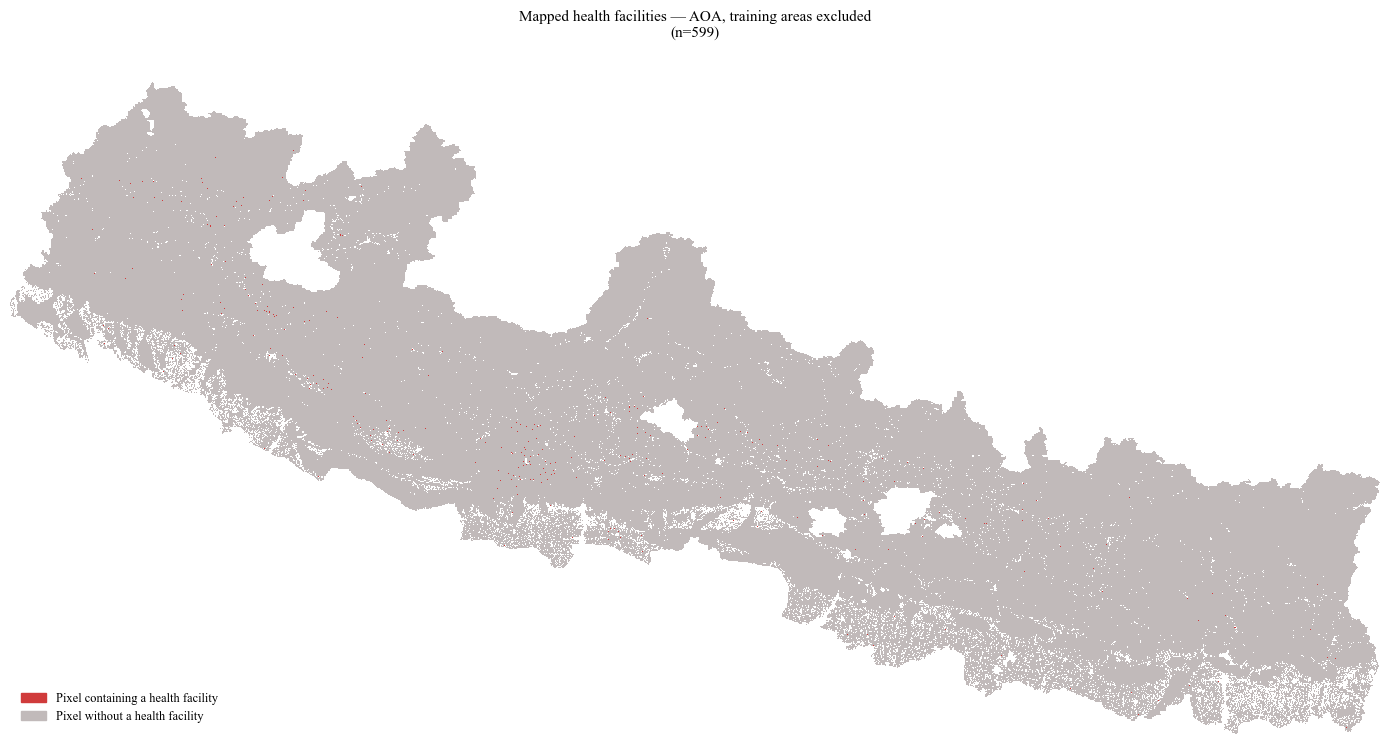

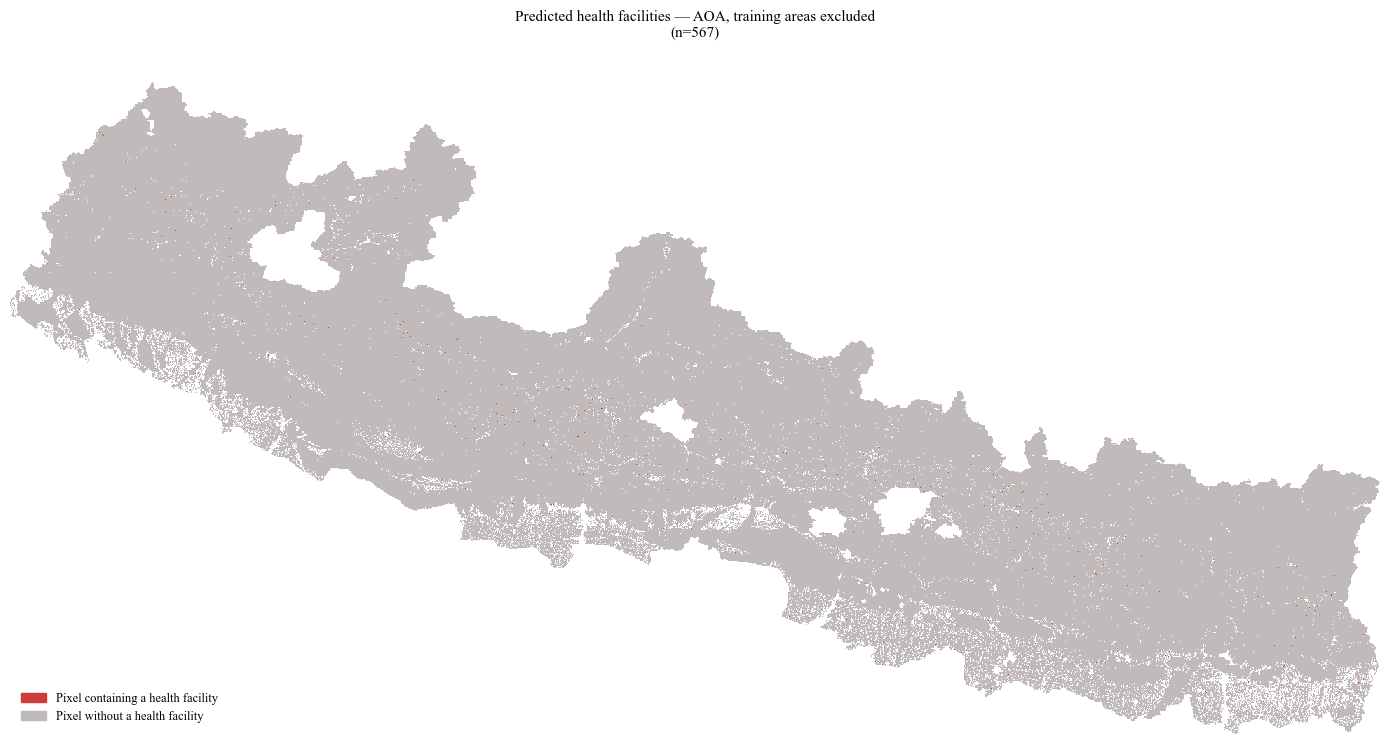

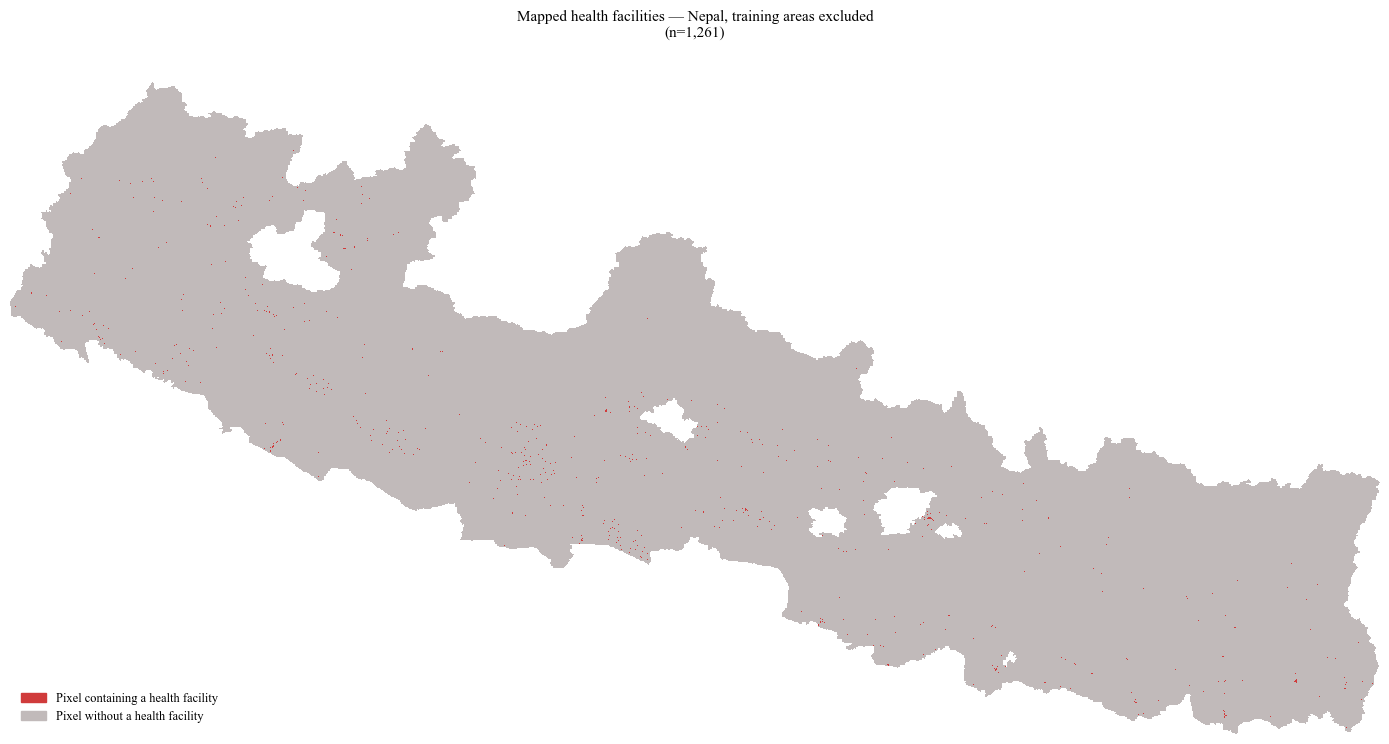

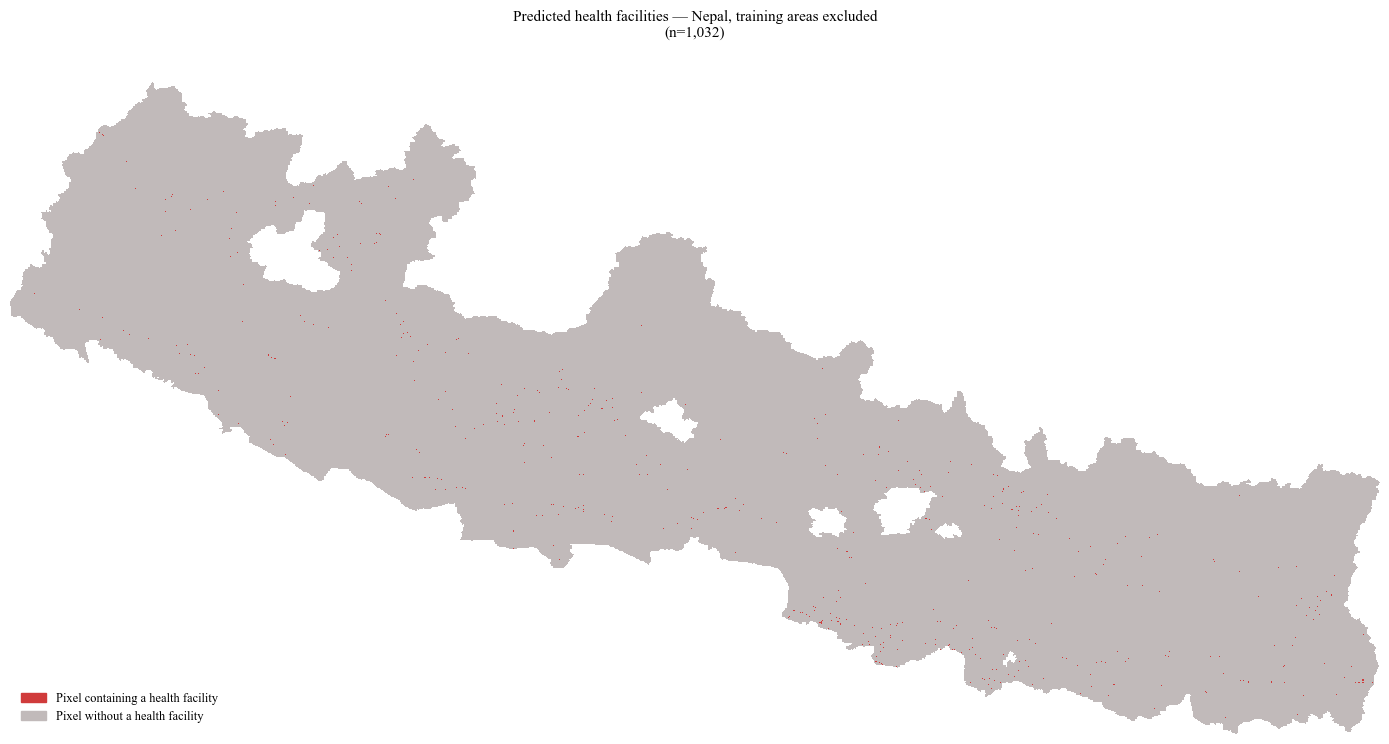

written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospitals_actual_eval_aoa.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_candidates_f1_eval_aoa.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospitals_actual_eval_nepal.tif
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\full_region\hospital_candidates_f1_eval_nepal.tif


In [34]:
from matplotlib.patches import Patch

layers = {
    "hospitals_actual": ("Mapped health facilities", hosp_actual_bool),
    "hospital_candidates_f1": ("Predicted health facilities", cand_f1_full),
}



def plot_layer(ax, name, em, title, layer):
    m = np.full(n_grid, np.nan)
    m[em] = layer[em]
    ax.imshow(m.reshape(nepal_shape), cmap=BINARY_CMAP, vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(f"{title} — {name}, training areas excluded\n(n={layer[em].sum():,})")
    ax.axis("off")
    ax.legend(handles=[Patch(color=THEME, label="Pixel containing a health facility"),
                       Patch(color=MAP_BG, label="Pixel without a health facility")],
              loc="lower left", frameon=False)


# Both variants
fig, axes = plt.subplots(2, 2, figsize=(19, 12))
for i, (name, em) in enumerate(eval_masks.items()):
    for j, (title, layer) in enumerate(layers.values()):
        plot_layer(axes[i, j], name, em, title, layer)
plt.tight_layout(); plt.show()

# Each map separately
for name, em in eval_masks.items():
    for title, layer in layers.values():
        fig, ax = plt.subplots(figsize=(14, 7.5))
        plot_layer(ax, name, em, title, layer)
        plt.tight_layout(); plt.show()

for name, em in eval_masks.items():
    for fname, (_, layer) in layers.items():
        write_raster(layer[em].astype(np.float32), em, nepal_shape, nepal_profile.copy(),
                     f"{nepal_dir}\\{fname}_eval_{name.lower()}.tif")

## 11. Export for the combined plots

In [35]:
MODEL = "hospital"
export_dir = Path(r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\model_outputs")
export_dir.mkdir(exist_ok=True)

# OOB probabilities and thresholds
np.savez(export_dir / f"{MODEL}_oob.npz",
         y=y.values, proba=proba, thr_f1=thr_f1, cap_used=CAP_PER_REGION)

# Permutation importance
perm_table = pd.DataFrame({"predictor": perm_importances.index,
                           "importance_mean": perm_importances.values,
                           "importance_std": perm_std.reindex(perm_importances.index).values})
perm_table.to_csv(export_dir / f"{MODEL}_perm_importance.csv", index=False)

# Correlation matrix of the predictors
corr_matrix.to_csv(export_dir / f"{MODEL}_predictor_correlation.csv")

# AOA share per cap
cap_sens.to_csv(export_dir / f"{MODEL}_aoa_cap_sensitivity.csv", index=False)

for f in sorted(export_dir.glob(f"{MODEL}_*")):
    print("written:", f)

written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\model_outputs\hospital_aoa_cap_sensitivity.csv
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\model_outputs\hospital_oob.npz
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\model_outputs\hospital_perm_importance.csv
written: C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data\model_outputs\hospital_predictor_correlation.csv
